<a href="https://colab.research.google.com/github/rushmilak/mmck_queue_simulation/blob/main/MMCK_Queue_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **M/M/C/K Queue Simulation**

In [16]:
# Parameters :
lambda_AR = 9     # arrival rate
mu_SR = 10        # service rate
c = 5             # number of servers
K = 20            # system capacity == receiving service + waiting


In [17]:
import heapq
import itertools
import math
import random
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

In [18]:
class Queue:
  def __init__(self, lambda_AR, mu_SR, C, K):
    self.lambda_AR = lambda_AR
    self.mu_SR = mu_SR
    self.C = C
    self.K = K
    assert C <= K

  # --------------------------------------------------------------
  def simulate(self, T_end, seed=42):
    lambda_AR, mu_SR, C, K = self.lambda_AR, self.mu_SR, self.C, self.K

    seq = itertools.count()
    rand = random.Random(seed)              # ONE generator for the whole run

    clock = 0.0
    n = 0                                   # people in system
    customer_data = []
    waiting = deque()
    events = []
    total_arrivals = blocked_arrivals = completed_services = 0
    free_servers = list(range(C))
    heapq.heapify(free_servers)

    n_vals, n_times = [0], [0.0]

    wait_total = 0.0
    served_started = 0

    last_t = 0.0
    area_n = 0.0
    area_busy = 0.0
    time_in_state = [0.0] * (K + 1)

    def push_event(time, event_type, customer_id=None):
      heapq.heappush(events, (time, next(seq), event_type, customer_id))

    push_event(rand.expovariate(lambda_AR), "arrival")

    def start_service(cid, t):
      nonlocal wait_total, served_started
      srv = heapq.heappop(free_servers)
      cu = customer_data[cid]
      cu["service_start"] = t
      cu["server"] = srv
      cu["departure_time"] = t + rand.expovariate(mu_SR)
      wait_total += t - cu["arrival_time"]
      served_started += 1
      push_event(cu["departure_time"], "departure", cid)

    while events:
      p_time, _, event_type, customer_id = heapq.heappop(events)

      if p_time > T_end:
        break

      dt = p_time - last_t
      area_n += n * dt
      area_busy += min(n, C) * dt
      time_in_state[n] += dt
      clock = last_t = p_time

      if event_type == "arrival":
        push_event(clock + rand.expovariate(lambda_AR), "arrival")
        total_arrivals += 1

        cu = {"id": len(customer_data), "arrival_time": clock,
              "service_start": math.inf, "departure_time": math.inf,
              "server": None, "blocked": False}
        customer_data.append(cu)

        if n == K:
          cu["blocked"] = True
          blocked_arrivals += 1
        else:
          n += 1
          if len(free_servers) > 0:
            start_service(cu["id"], clock)
          else:
            waiting.append(cu["id"])

      else:  # departure
        completed_services += 1
        n -= 1
        heapq.heappush(free_servers, customer_data[customer_id]["server"])
        if waiting:
          start_service(waiting.popleft(), clock)

      n_times.append(clock)
      n_vals.append(n)

    # close the final interval
    dt = T_end - last_t
    area_n += n * dt
    area_busy += min(n, C) * dt
    time_in_state[n] += dt
    n_times.append(T_end)
    n_vals.append(n)

    queue_info = {
      "total_arrivals": total_arrivals,
      "total_blocked": blocked_arrivals,
      "completed_services": completed_services,
      "total_wait_time": wait_total,
      "throughput": completed_services / T_end,
      "prob_state_n": [x / T_end for x in time_in_state],
      "block_prob": blocked_arrivals / total_arrivals if total_arrivals else 0.0,
      "average_n": area_n / T_end,
      "average_wait_time_per_customer": wait_total / served_started if served_started else 0.0,
      "capacity_utilization": area_busy / T_end / C,
    }
    return customer_data, np.array(n_times), np.array(n_vals), queue_info

  # --------------------------------------------------------------
  def analytical_soln(self):
    lambda_AR, mu_SR, C, K = self.lambda_AR, self.mu_SR, self.C, self.K
    r = lambda_AR / mu_SR                      # offered load

    probs = []
    for n in range(K + 1):
      if n < C:
        probs.append(r ** n / math.factorial(n))
      else:
        probs.append(r ** n / (math.factorial(C) * C ** (n - C)))

    total = sum(probs)
    p = [x / total for x in probs]

    L = sum(n * pn for n, pn in enumerate(p))                      # mean number in system
    effective_lambda = lambda_AR * (1 - p[K])                      # effective arrival rate
    Lq = sum((n - C) * p[n] for n in range(C + 1, K + 1))          # mean number in queue
    Wq = Lq / effective_lambda                                     # mean wait in queue
    W = L / effective_lambda                                       # mean time in system

    return {
      "block_prob": p[K],
      "capacity_utilization": effective_lambda / (C * mu_SR),
      "throughput": effective_lambda,
      "mean_n": L,
      "mean_wait": Wq,
      "mean_sys_time": W,
      "prob_state_n": p,
    }

M/M/3/8  lambda=4.0  mu=1.5  T=20000  seed=42

metric                      simulated  analytical    error
Blocking probability           0.0808      0.0811    0.38%
Server utilization             0.8140      0.8168    0.35%
Throughput                     3.6719      3.6758    0.10%
Mean # in system (L)           3.8645      3.8891    0.63%
Mean wait in queue (Wq)        0.3874      0.3914    1.01%


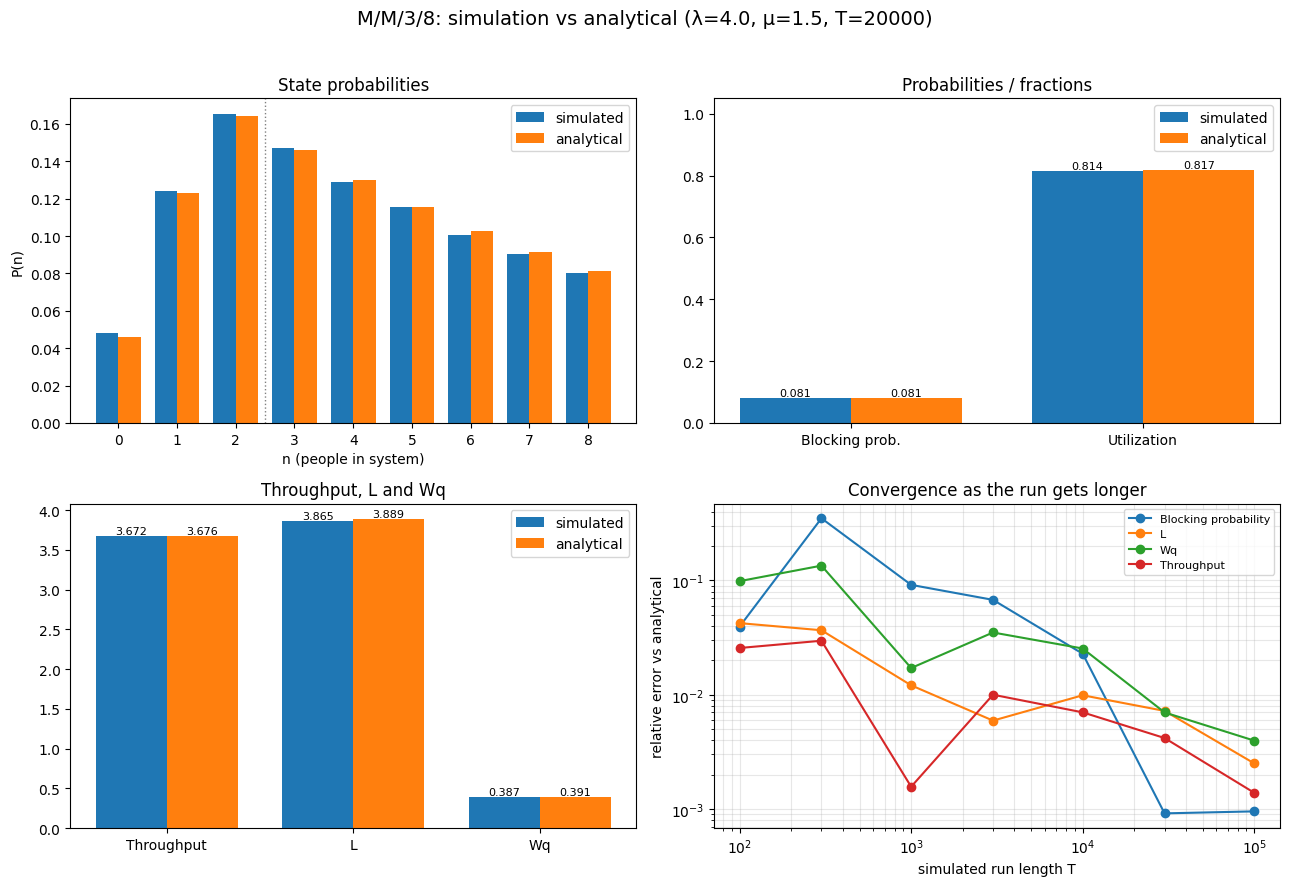

In [19]:
import math
import numpy as np
import matplotlib.pyplot as plt

# ---------------- parameters ----------------
LAM, MU, C, K = 4.0, 1.5, 3, 8
T_END, SEED = 20000, 42
T_LIST = [100, 300, 1000, 3000, 10000, 30000, 100000]   # for the convergence plot

q = Queue(LAM, MU, C, K)


def sim_metrics(T, seed):
    """Run the simulation and compute every metric from what simulate() returns."""
    out = q.simulate(T, seed)
    cd, nt, nv = out[0], np.asarray(out[1], float), np.asarray(out[2])
    dt, n_in = np.diff(nt), nv[:-1]          # n(t) = nv[i] on the interval (nt[i], nt[i+1])

    P = np.array([dt[n_in == i].sum() for i in range(K + 1)]) / T
    started = [c["service_start"] - c["arrival_time"] for c in cd if c["service_start"] < math.inf]
    return {
        "P_n": P,
        "block_prob": sum(c["blocked"] for c in cd) / len(cd),
        "utilization": (np.minimum(n_in, C) * dt).sum() / T / C,
        "throughput": sum(c["departure_time"] <= T for c in cd) / T,
        "L": (n_in * dt).sum() / T,
        "Wq": float(np.mean(started)),
    }


# ---------------- main comparison ----------------
sim = sim_metrics(T_END, SEED)
ana = q.analytical_soln()

rows = [("Blocking probability", sim["block_prob"], ana["block_prob"]),
        ("Server utilization",   sim["utilization"], ana["capacity_utilization"]),
        ("Throughput",           sim["throughput"], ana["throughput"]),
        ("Mean # in system (L)", sim["L"], ana["mean_n"]),
        ("Mean wait in queue (Wq)", sim["Wq"], ana["mean_wait"])]

print(f"M/M/{C}/{K}  lambda={LAM}  mu={MU}  T={T_END}  seed={SEED}\n")
print(f"{'metric':<26}{'simulated':>11}{'analytical':>12}{'error':>9}")
for name, s, a in rows:
    print(f"{name:<26}{s:>11.4f}{a:>12.4f}{abs(s - a) / a * 100:>8.2f}%")

# convergence runs
conv = {"Blocking probability": [], "L": [], "Wq": [], "Throughput": []}
for i, T in enumerate(T_LIST):
    s = sim_metrics(T, SEED + i + 1)
    conv["Blocking probability"].append(abs(s["block_prob"] - ana["block_prob"]) / ana["block_prob"])
    conv["L"].append(abs(s["L"] - ana["mean_n"]) / ana["mean_n"])
    conv["Wq"].append(abs(s["Wq"] - ana["mean_wait"]) / ana["mean_wait"])
    conv["Throughput"].append(abs(s["throughput"] - ana["throughput"]) / ana["throughput"])

# ---------------- plots ----------------
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle(f"M/M/{C}/{K}: simulation vs analytical (λ={LAM}, μ={MU}, T={T_END})", fontsize=14)
w = 0.38


def paired_bars(ax, labels, s_vals, a_vals):
    x = np.arange(len(labels))
    ax.bar(x - w / 2, s_vals, w, label="simulated", color="tab:blue")
    ax.bar(x + w / 2, a_vals, w, label="analytical", color="tab:orange")
    for xi, (s, a) in enumerate(zip(s_vals, a_vals)):
        ax.text(xi - w / 2, s, f"{s:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(xi + w / 2, a, f"{a:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()


ax = axs[0, 0]
st = np.arange(K + 1)
ax.bar(st - w / 2, sim["P_n"], w, label="simulated", color="tab:blue")
ax.bar(st + w / 2, ana["prob_state_n"], w, label="analytical", color="tab:orange")
ax.axvline(C - 0.5, color="gray", ls=":", lw=1)
ax.set(xlabel="n (people in system)", ylabel="P(n)", title="State probabilities", xticks=st)
ax.legend()

ax = axs[0, 1]
paired_bars(ax, ["Blocking prob.", "Utilization"],
            [rows[0][1], rows[1][1]], [rows[0][2], rows[1][2]])
ax.set_ylim(0, 1.05)
ax.set_title("Probabilities / fractions")

ax = axs[1, 0]
paired_bars(ax, ["Throughput", "L", "Wq"],
            [rows[2][1], rows[3][1], rows[4][1]], [rows[2][2], rows[3][2], rows[4][2]])
ax.set_title("Throughput, L and Wq")

ax = axs[1, 1]
for name, errs in conv.items():
    ax.plot(T_LIST, np.maximum(errs, 1e-5), marker="o", label=name)
ax.set(xscale="log", yscale="log", xlabel="simulated run length T",
       ylabel="relative error vs analytical", title="Convergence as the run gets longer")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()